# Refresher RP4: Spin and Thermal Statistics

**Part:** Physics refresher · **Reading time:** ~30 min · **Pass 1 overview:** [What MRI Measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb) · **Refreshers you may want:** [Precession and torque](../refreshers/RP3_Precession_and_Torque.ipynb), [Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb)

Why does a body in a 3 T scanner become (very slightly) magnetic? Because nuclear spins have a little more probability to point along the field than against it. "A little" means about **10 parts per million** at 3 T and body temperature: of every million protons, only ~10 net "vote" for the field. This refresher explains where that number comes from — nuclear spin, its energy levels in $B_0$, and the Boltzmann distribution — derives the equilibrium magnetization $M_0$ (with every step the original book skips), and shows why the enormous number of protons still gives a measurable signal. It ends with why the "spins point up or down" picture is misleading and why the classical Bloch equation works anyway.

## Learning goals

1. Explain what nuclear spin is, which nuclei have it, and what the spin quantum number $I$ means.
2. Derive the energy levels of a spin-½ nucleus in $B_0$ and the gap $\Delta E=\hbar\gamma B_0=hf_0$.
3. Understand the Boltzmann distribution from scratch and compute the population ratio $N_\uparrow/N_\downarrow$.
4. Compute the fractional polarization $\approx\hbar\gamma B_0/(2k_BT)$ at 1.5/3/7 T and derive $M_0=N\gamma^2\hbar^2I(I+1)B_0/(3k_BT)$.
5. Count the excess spins in a voxel and explain why the tiny polarization is enough.
6. Explain why the ensemble magnetization behaves classically, and what hyperpolarization is.

## Symbols used in this refresher

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $I$ | spin quantum number of a nucleus | – | ½ for ¹H (original writes $I_Z$, see §5) |
| $m_I$ | magnetic quantum number: $z$-component of spin in units of $\hbar$, $m_I=-I,\dots,+I$ | – | ±½ for ¹H |
| $\vec L$ | spin angular momentum | J s | $\lvert\vec L\rvert=\hbar\sqrt{I(I+1)}$, $L_z=m_I\hbar$ |
| $\vec\mu$, $\mu_z$ | nuclear magnetic moment, its $z$-component | J/T | $\mu_z=\gamma\hbar m_I$; proton $\pm1.41\times10^{-26}$ J/T |
| $h$, $\hbar=h/2\pi$ | Planck constant, reduced Planck constant | J s | $6.626\times10^{-34}$, $1.055\times10^{-34}$ |
| $\gamma$, $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio | rad s⁻¹ T⁻¹, Hz/T | $2.675\times10^8$; 42.58 MHz/T for ¹H |
| $B_0$ | main static field (along $z$) | T | 1.5, 3, 7 T |
| $f_0=\bar\gamma B_0$, $\omega_0=\gamma B_0$ | Larmor frequency | Hz, rad/s | 127.7 MHz at 3 T |
| $E$, $\Delta E$ | energy of a spin state; gap between the two states of a spin-½ | J | $\Delta E=\hbar\gamma B_0$ |
| $k_B$ | Boltzmann constant | J/K | $1.381\times10^{-23}$ (original writes $k$) |
| $T$ | absolute temperature | K | 310 K body. ⚠️ not tesla, not $T_1$/$T_2$ |
| $N_\uparrow$, $N_\downarrow$ | number of spins in the lower ("parallel") / upper ("antiparallel") energy state | – | |
| $P$ | fractional polarization $(N_\uparrow-N_\downarrow)/(N_\uparrow+N_\downarrow)$ | – | ≈ 10⁻⁵ at 3 T |
| $x$ | ratio $\Delta E/(k_BT)$ | – | ≈ 2×10⁻⁵ at 3 T |
| $N$ (or $N(\vec r)$) | spin density: number of nuclei per volume | m⁻³ | water ¹H: $6.69\times10^{28}$ |
| $\langle\cdot\rangle$ | average (expectation value) over the ensemble | | |
| $M_0$ | equilibrium magnetization (magnetic moment per volume) | A/m | ≈ 9.3 mA/m for water at 3 T (normalized to 1 in later chapters) |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $V_{vox}$ | voxel volume | m³ | 1 mm³ = 10⁻⁹ m³ |
| $\Omega_{res}$, $S$ | number of microstates of a reservoir; entropy $S=k_B\ln\Omega_{res}$ | –, J/K | only in the Boltzmann derivation |
| $N_A$ | Avogadro constant | mol⁻¹ | $6.022\times10^{23}$ |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. What is nuclear spin?

Protons and neutrons — and therefore many nuclei — carry an **intrinsic angular momentum** called **spin**. "Intrinsic" means it is a built-in property like charge or mass: it cannot be sped up, slowed down or switched off. It is *not* literally a little ball rotating (that picture gives wrong numbers), but it behaves like angular momentum in every measurable way, including the gyroscopic precession of [RP3](../refreshers/RP3_Precession_and_Torque.ipynb). Because nuclei are charged, spin comes with a **magnetic moment** $\vec\mu=\gamma\vec L$.

Quantum mechanics says spin is **quantized**:

* Each nucleus has a **spin quantum number** $I$ = 0, ½, 1, 3/2, … The size of its spin is $|\vec L|=\hbar\sqrt{I(I+1)}$.
* If you measure the component along any axis (we pick $z$ = direction of $B_0$), you only ever find $L_z=m_I\hbar$ with $m_I\in\{-I,-I+1,\dots,+I\}$: $2I+1$ possible values. For a spin-½ nucleus such as ¹H: $m_I=\pm\tfrac12$, two values, usually called "up" and "down".

**Which nuclei have spin?** Protons pair up with protons and neutrons with neutrons with opposite spins, so:

| Protons | Neutrons | Spin $I$ | Examples |
|---|---|---|---|
| even | even | 0 — **invisible to MRI** | ¹²C, ¹⁶O (most carbon and oxygen in the body) |
| odd mass number (one of them odd) | | half-integer (½, 3/2, 5/2, …) | ¹H (½), ¹³C (½), ¹⁹F (½), ³¹P (½), ²³Na (3/2), ¹⁷O (5/2), ¹²⁹Xe (½) |
| odd | odd | integer (1, 2, 3, …) | ²H (1), ¹⁴N (1) |

(The *exact* value of $I$ is not predicted by this simple rule; it is measured.)

In [2]:
# spin I, natural isotopic abundance, gamma-bar [Hz/T]
nuclei = {
    "1H":    (0.5, 0.99985, mt.GAMMA_BAR_NUCLEI["1H"]),
    "2H":    (1.0, 0.000156, mt.GAMMA_BAR_NUCLEI["2H"]),
    "13C":   (0.5, 0.0107, mt.GAMMA_BAR_NUCLEI["13C"]),
    "14N":   (1.0, 0.996, 3.077e6),
    "17O":   (2.5, 0.00038, -5.772e6),
    "19F":   (0.5, 1.0, mt.GAMMA_BAR_NUCLEI["19F"]),
    "23Na":  (1.5, 1.0, mt.GAMMA_BAR_NUCLEI["23Na"]),
    "31P":   (0.5, 1.0, mt.GAMMA_BAR_NUCLEI["31P"]),
    "129Xe": (0.5, 0.264, mt.GAMMA_BAR_NUCLEI["129Xe"]),
}
gb_H = mt.GAMMA_BAR_NUCLEI["1H"]
print(f"{'nucleus':8s} {'I':>4s} {'abundance':>10s} {'gamma-bar [MHz/T]':>18s} {'rel. sensitivity*':>18s}")
for name, (I, ab, gb) in nuclei.items():
    # NMR receptivity at equal B0 and equal number of atoms of that element: ~ |gamma|^3 I(I+1) x abundance
    rel = abs(gb / gb_H)**3 * (I * (I + 1)) / 0.75 * ab / 0.99985
    print(f"{name:8s} {I:4.1f} {ab * 100:9.3g}% {gb / 1e6:18.3f} {rel:18.2e}")
print("* relative to 1H, per atom of the element, same B0 (signal ~ gamma^2 I(I+1) from M0, x gamma from induction).")

nucleus     I  abundance  gamma-bar [MHz/T]  rel. sensitivity*
1H        0.5       100%             42.577           1.00e+00
2H        1.0    0.0156%              6.536           1.51e-06
13C       0.5      1.07%             10.708           1.70e-04
14N       1.0      99.6%              3.077           1.00e-03
17O       2.5     0.038%             -5.772           1.10e-05
19F       0.5       100%             40.078           8.34e-01
23Na      1.5       100%             11.262           9.25e-02
31P       0.5       100%             17.235           6.63e-02
129Xe     0.5      26.4%            -11.777           5.59e-03
* relative to 1H, per atom of the element, same B0 (signal ~ gamma^2 I(I+1) from M0, x gamma from induction).


Hydrogen wins by a wide margin: it has the largest $\gamma$ of the stable nuclei, ~100 % abundance, and it is the most common atom in the body (≈ 63 % of all atoms, mostly in water and fat). Other nuclei are imaged only in specialized ("X-nuclear") studies, at much lower resolution.

> **⚠️ Common confusion:** The original book states that hydrogen makes up "about 80 % of the atoms in our bodies". By number of atoms the usual figure is ≈ 62–63 % (oxygen ≈ 24 %, carbon ≈ 12 %). By mass hydrogen is only ≈ 10 %.

## 2. Energy levels in a magnetic field

A magnetic moment in a field has energy $E=-\vec\mu\cdot\vec B$ ([RP3](../refreshers/RP3_Precession_and_Torque.ipynb)). With $\vec B = B_0\hat z$ and $\mu_z=\gamma\hbar m_I$:

$$E_{m_I} = -\mu_z B_0 = -\gamma\hbar\,m_I\,B_0 .$$

In words: each allowed $z$-orientation of the spin has its own energy; for positive $\gamma$ the state with $m_I=+\tfrac12$ (moment along $B_0$) is the lower one.
Where: $E_{m_I}$ = energy [J], $\gamma$ [rad s⁻¹ T⁻¹], $\hbar=1.055\times10^{-34}$ J s, $m_I$ = magnetic quantum number, $B_0$ [T].

For spin ½ the two levels are $E=\mp\tfrac12\hbar\gamma B_0$ and the gap is

$$\Delta E = \hbar\gamma B_0 = h\bar\gamma B_0 = h f_0 .$$

In words: the energy difference between "down" and "up" grows linearly with the field, and it equals exactly the energy of one photon at the Larmor frequency. (The **Zeeman splitting**.)
Where: $h = 2\pi\hbar = 6.626\times10^{-34}$ J s, $\bar\gamma=\gamma/2\pi$ [Hz/T], $f_0=\bar\gamma B_0$ [Hz]. The two forms are identical because $h\bar\gamma = (2\pi\hbar)(\gamma/2\pi) = \hbar\gamma$.

> **🧭 Intuition — two pictures, one frequency:** Classically, the moment precesses at $f_0=\bar\gamma B_0$ ([RP3](../refreshers/RP3_Precession_and_Torque.ipynb)), and a rotating $B_1$ at that frequency drives it efficiently (resonance). Quantum-mechanically, a photon of energy $hf$ can drive transitions between the two levels only if $hf=\Delta E$, i.e. again $f=\bar\gamma B_0$. The resonance condition is the same in both pictures — not a coincidence, but a consequence of quantum mechanics reproducing classical mechanics for the average spin (section 7).

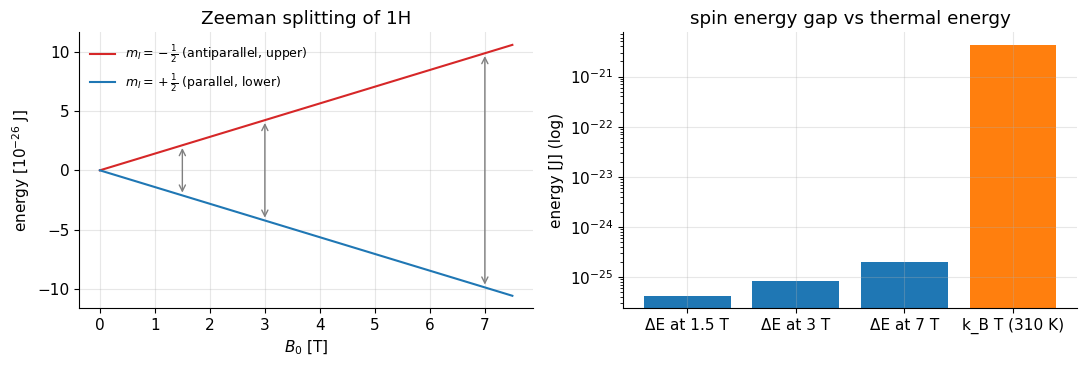

B0 = 1.5 T: dE = 4.23e-26 J = h x 63.9 MHz;  dE / (k_B T) = 9.89e-06
B0 = 3.0 T: dE = 8.46e-26 J = h x 127.7 MHz;  dE / (k_B T) = 1.98e-05
B0 = 7.0 T: dE = 1.97e-25 J = h x 298.0 MHz;  dE / (k_B T) = 4.61e-05


In [3]:
kT = mt.K_BOLTZMANN * 310                 # thermal energy at body temperature [J]
B = np.linspace(0, 7.5, 200)
dE = mt.HBAR * mt.GAMMA * B               # energy gap [J]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(B, +dE / 2 / 1e-26, "C3", label=r"$m_I=-\frac{1}{2}$ (antiparallel, upper)")
axs[0].plot(B, -dE / 2 / 1e-26, "C0", label=r"$m_I=+\frac{1}{2}$ (parallel, lower)")
axs[0].set_xlabel(r"$B_0$ [T]"); axs[0].set_ylabel(r"energy [$10^{-26}$ J]"); axs[0].set_title("Zeeman splitting of 1H")
axs[0].legend(fontsize=9)
for B0 in [1.5, 3, 7]:
    axs[0].annotate("", xy=(B0, mt.HBAR * mt.GAMMA * B0 / 2 / 1e-26), xytext=(B0, -mt.HBAR * mt.GAMMA * B0 / 2 / 1e-26),
                    arrowprops=dict(arrowstyle="<->", color="gray"))
axs[1].bar(["ΔE at 1.5 T", "ΔE at 3 T", "ΔE at 7 T", "k_B T (310 K)"],
           [mt.HBAR * mt.GAMMA * b for b in (1.5, 3, 7)] + [kT], color=["C0", "C0", "C0", "C1"])
axs[1].set_yscale("log"); axs[1].set_ylabel("energy [J] (log)"); axs[1].set_title("spin energy gap vs thermal energy")
plt.tight_layout(); plt.show()
for B0 in [1.5, 3.0, 7.0]:
    d = mt.HBAR * mt.GAMMA * B0
    print(f"B0 = {B0} T: dE = {d:.2e} J = h x {d / mt.H_PLANCK / 1e6:.1f} MHz;  dE / (k_B T) = {d / kT:.2e}")

The energy gap is tiny: at 3 T it is **50 000 times smaller** than the typical thermal energy $k_BT$ at body temperature. Thermal jostling therefore almost completely randomizes the spins; only a tiny bias toward the lower level survives. To quantify "tiny bias" we need the Boltzmann distribution.

## 3. The Boltzmann distribution, from scratch

Consider one small system (here: one nuclear spin) that can exchange energy with a huge environment (the "lattice": the molecules around it, all jiggling at temperature $T$). Statistical physics tells us:

> In thermal equilibrium at temperature $T$, the probability of finding the small system in a particular state with energy $E$ is proportional to $e^{-E/k_BT}$.

$$p(E) \propto e^{-E/(k_BT)} .$$

In words: higher-energy states are exponentially less likely; $k_BT$ is the energy scale that decides what counts as "high". States with $E\ll k_BT$ above the ground state are almost as likely as the ground state.
Where: $p$ = probability, $E$ = energy of the state [J], $k_B=1.381\times10^{-23}$ J/K, $T$ = absolute temperature [K]; $k_BT = 4.3\times10^{-21}$ J at 310 K.

<details><summary><b>📐 Why an exponential? (optional)</b></summary>

Let the environment have $\Omega_{res}(E_{res})$ microscopic arrangements ("microstates") when it holds energy $E_{res}$. Total energy is fixed, $E_{res}=E_{tot}-E$. If every microstate of the whole is equally likely, the probability of finding the small system in one particular state of energy $E$ is proportional to the number of ways the environment can hold the rest: $p(E)\propto\Omega_{res}(E_{tot}-E)$.

Take the logarithm and Taylor-expand (the small system's $E$ is tiny compared with $E_{tot}$):

$$\ln\Omega_{res}(E_{tot}-E)\approx\ln\Omega_{res}(E_{tot}) - E\,\frac{d\ln\Omega_{res}}{dE_{res}} .$$

Temperature is *defined* through entropy $S=k_B\ln\Omega_{res}$ by $1/T = dS/dE_{res}$, so $d\ln\Omega_{res}/dE_{res}=1/(k_BT)$. Exponentiating, $p(E)\propto e^{-E/k_BT}$. In words: giving energy $E$ to the spin takes it from the environment, which costs a factor $e^{-E/k_BT}$ in the environment's number of possible arrangements.

</details>

### Demo: the exponential emerges from random energy sharing

A toy model: 5000 "particles" each start with 5 units of energy; at each step random pairs meet and one unit moves from one to the other (if it has any). No rule favours anybody, yet the energy of any one particle ends up exponentially distributed — the Boltzmann distribution, with $k_BT$ equal to the mean energy per particle.

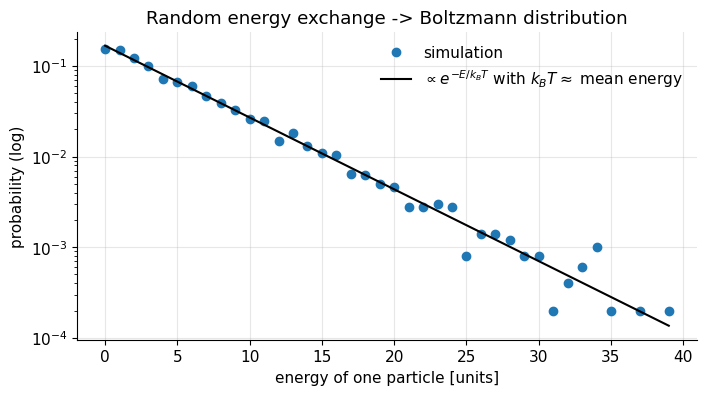

In [4]:
rng = np.random.default_rng(1)
n_part, e_mean = 5000, 5
energy = np.full(n_part, e_mean)
for sweep in range(3000):
    perm = rng.permutation(n_part)
    giver, taker = perm[: n_part // 2], perm[n_part // 2:]      # disjoint random pairs
    move = energy[giver] > 0                                    # only give if you have something
    energy[giver[move]] -= 1
    energy[taker[move]] += 1

E_vals = np.arange(0, 40)
hist = np.bincount(energy, minlength=40)[:40] / n_part
p_boltz = (1 / (e_mean + 1)) * (e_mean / (e_mean + 1))**E_vals   # discrete exponential with the same mean
plt.semilogy(E_vals, hist, "o", label="simulation")
plt.semilogy(E_vals, p_boltz, "k-", label=r"$\propto e^{-E/k_BT}$ with $k_BT\approx$ mean energy")
plt.xlabel("energy of one particle [units]"); plt.ylabel("probability (log)")
plt.title("Random energy exchange -> Boltzmann distribution"); plt.legend(); plt.show()

On a log scale the probability falls on a straight line: an exponential. Nothing in the rules was exponential; it comes purely from counting the ways the *rest* of the system can hold the remaining energy.

Applied to a spin-½ nucleus with its two levels $E=\mp\tfrac12\Delta E$:

$$\frac{N_\uparrow}{N_\downarrow} = \frac{e^{+\Delta E/2k_BT}}{e^{-\Delta E/2k_BT}} = e^{\Delta E/k_BT} = e^{\hbar\gamma B_0/k_BT}.$$

In words: the ratio of the numbers of spins in the lower and upper states is the Boltzmann factor of their energy difference.
Where: $N_\uparrow$ = number of spins in the lower ("parallel", $m_I=+\frac12$) state, $N_\downarrow$ = number in the upper state, $\Delta E=\hbar\gamma B_0$ [J]. At 3 T and 310 K, $\Delta E/k_BT\approx2\times10^{-5}$, so $N_\uparrow/N_\downarrow\approx1.00002$.

## 4. Fractional polarization

The **fractional polarization** is the excess of lower-state spins as a fraction of all spins:

$$P = \frac{N_\uparrow-N_\downarrow}{N_\uparrow+N_\downarrow} = \frac{e^{x/2}-e^{-x/2}}{e^{x/2}+e^{-x/2}} = \tanh\!\left(\frac{x}{2}\right) \approx \frac{x}{2} = \frac{\hbar\gamma B_0}{2k_BT},\qquad x=\frac{\Delta E}{k_BT}.$$

In words: the polarization is the hyperbolic tangent of half the energy-to-thermal ratio; because that ratio is tiny, $\tanh$ is in its linear range and the polarization is simply **proportional to $B_0$ and inversely proportional to $T$**.
Where: $P$ = polarization (dimensionless, between 0 and 1), $x=\hbar\gamma B_0/(k_BT)$. The step to $\tanh$: divide numerator and denominator by $N_\uparrow+N_\downarrow$ and use $N_\uparrow\propto e^{x/2}$, $N_\downarrow\propto e^{-x/2}$. The approximation $\tanh(u)\approx u$ holds for $|u|\ll1$ (error $\approx u^3/3$). (The original writes the same thing as $\frac{1-e^{-x}}{1+e^{-x}}$ — multiply numerator and denominator of our form by $e^{-x/2}$.)

In [5]:
T_body = 310.0
print(f"{'B0 [T]':>7s} {'f0 [MHz]':>9s} {'P exact (tanh)':>15s} {'P approx x/2':>13s}  {'in ppm':>7s}")
for B0 in [0.55, 1.5, 3.0, 7.0, 11.7]:
    x = mt.HBAR * mt.GAMMA * B0 / (mt.K_BOLTZMANN * T_body)
    print(f"{B0:7.2f} {mt.larmor_frequency(B0) / 1e6:9.1f} {np.tanh(x / 2):15.4e} {x / 2:13.4e}  {np.tanh(x / 2) * 1e6:7.2f}")

 B0 [T]  f0 [MHz]  P exact (tanh)  P approx x/2   in ppm
   0.55      23.4      1.8127e-06    1.8127e-06     1.81
   1.50      63.9      4.9436e-06    4.9436e-06     4.94
   3.00     127.7      9.8873e-06    9.8873e-06     9.89
   7.00     298.0      2.3070e-05    2.3070e-05    23.07
  11.70     498.2      3.8560e-05    3.8560e-05    38.56


At body temperature the polarization is **≈ 3.3 ppm per tesla**: 4.9 ppm at 1.5 T, 9.9 ppm at 3 T, 23 ppm at 7 T. The approximation is perfect here. Now let us see how polarization depends on field *and* temperature, and where hyperpolarization methods sit:

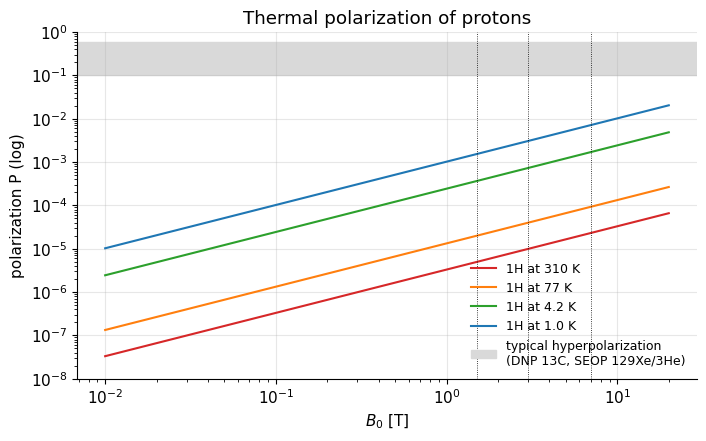

In [6]:
B_axis = np.logspace(-2, np.log10(20), 300)                 # 10 mT ... 20 T
plt.figure(figsize=(8, 4.5))
for T_K, col in [(310, "C3"), (77, "C1"), (4.2, "C2"), (1.0, "C0")]:
    x = mt.HBAR * mt.GAMMA * B_axis / (mt.K_BOLTZMANN * T_K)
    plt.loglog(B_axis, np.tanh(x / 2), color=col, label=f"1H at {T_K} K")
plt.axhspan(0.1, 0.6, color="0.85", label="typical hyperpolarization\n(DNP 13C, SEOP 129Xe/3He)")
for B0 in [1.5, 3, 7]:
    plt.axvline(B0, color="k", lw=0.6, ls=":")
plt.xlabel(r"$B_0$ [T]"); plt.ylabel("polarization P (log)")
plt.title("Thermal polarization of protons"); plt.legend(fontsize=9, loc="lower right"); plt.ylim(1e-8, 1)
plt.show()

The straight lines (slope 1 on log–log) show $P\propto B_0/T$. Cooling a *patient* is not an option, which is one reason we push $B_0$ higher. Note that even at 1 K and 20 T, protons are only ~1–2 % polarized; at very low temperature and high field the curve bends ($\tanh$ saturates at 1).

## 5. Equilibrium magnetization $M_0$

The **net magnetization** is the total magnetic moment per volume. In equilibrium it points along $B_0$ and has size

$$M_0 = N\,\langle\mu_z\rangle ,$$

where $N$ is the spin density [m⁻³] and $\langle\mu_z\rangle$ the average $z$-moment per spin [J/T]. For spin ½, each spin contributes $\pm\frac12\gamma\hbar$, so $\langle\mu_z\rangle=\frac12\gamma\hbar\,P$ and

$$M_0 = N\,\frac{\gamma\hbar}{2}\,\frac{\gamma\hbar B_0}{2k_BT} = \frac{N\gamma^2\hbar^2B_0}{4k_BT}.$$

For a general spin $I$ the same reasoning gives

$$\boxed{M_0 = \frac{N\,\gamma^2\hbar^2\,I(I+1)\,B_0}{3\,k_BT}}$$

In words: the equilibrium magnetization is proportional to the number of spins, to the **square** of the gyromagnetic ratio (once for the size of each moment, once for the energy gap that creates the bias), to the field, and inversely to temperature (**Curie's law**).
Where: $M_0$ [A/m], $N$ = spin density [m⁻³], $\gamma$ [rad s⁻¹ T⁻¹], $\hbar$ [J s], $I$ = spin quantum number, $B_0$ [T], $k_B$ [J/K], $T$ [K]. Check: $I=\frac12$ gives $I(I+1)/3=\frac14$, the spin-½ result.

<details><summary><b>📐 Derivation for general spin I (optional)</b></summary>

There are $2I+1$ states $m_I=-I..I$ with energies $E_m=-\gamma\hbar m B_0$ and Boltzmann probabilities $p_m = e^{xm}/\sum_{m'}e^{xm'}$, with $x=\gamma\hbar B_0/k_BT\ll1$. Expand $e^{xm}\approx1+xm$:

$$\langle m\rangle=\frac{\sum_m m\,(1+xm)}{\sum_m(1+xm)} = \frac{0 + x\sum_m m^2}{(2I+1) + 0} = x\,\frac{I(I+1)}{3},$$

using $\sum_{m=-I}^{I}m=0$ and $\sum_{m=-I}^{I}m^2=\frac{I(I+1)(2I+1)}{3}$. Then $\langle\mu_z\rangle=\gamma\hbar\langle m\rangle=\frac{\gamma^2\hbar^2I(I+1)B_0}{3k_BT}$ and $M_0=N\langle\mu_z\rangle$.

Classical cross-check: a classical moment of fixed size $\mu$ with random orientation, Boltzmann-weighted by $e^{\mu B\cos\theta/k_BT}$, has $\langle\cos\theta\rangle\approx\mu B/(3k_BT)$, so $M=N\mu^2B/(3k_BT)$. With the quantum size $\mu^2 = \gamma^2\hbar^2 I(I+1)$ this is *identical* — a first hint that the ensemble behaves classically (section 7).

</details>

> **⚠️ Common confusion — comparing with the original book:** The original writes $M_0 = \frac{N\bar\gamma^2h^2 I_Z(I_Z+1)B_0}{3kT}$. This is the **same formula**: $\bar\gamma h = (\gamma/2\pi)(2\pi\hbar)=\gamma\hbar$, so $\bar\gamma^2h^2=\gamma^2\hbar^2$. But the symbol $I_Z$ is wrong: what enters is the spin quantum number $I$ (½ for ¹H), *not* a $z$-component ($I_z$ conventionally denotes the $z$-component of the spin, whose quantum number is $m_I$). Also, the original lists $k$ both in eV/K and J/K; with $h$ in J s you must use $k_B=1.381\times10^{-23}$ J/K. And the unit of $M$ is A/m (not tesla); $\mu_0M$ is in tesla.

### Numbers for water at 3 T

The spin density of ¹H in water: 1 m³ of water = 1000 kg = 1000/0.018 mol = 55 500 mol, each H₂O molecule has 2 protons.

In [7]:
N_water = 1000 / 0.018015 * mt.AVOGADRO * 2           # 1H per m^3 of water
print(f"1H spin density of water: N = {N_water:.3e} per m^3")
T_body, B0, I_spin = 310.0, 3.0, 0.5

def M0_curie(N, B0, T, gamma=mt.GAMMA, I=0.5):
    """Equilibrium magnetization [A/m], high-temperature (Curie) law."""
    return N * gamma**2 * mt.HBAR**2 * I * (I + 1) * B0 / (3 * mt.K_BOLTZMANN * T)

M0 = M0_curie(N_water, B0, T_body)
# the original book's form (gamma-bar and h) gives the same number:
M0_orig = N_water * mt.GAMMA_BAR**2 * mt.H_PLANCK**2 * I_spin * (I_spin + 1) * B0 / (3 * mt.K_BOLTZMANN * T_body)
print(f"M0 = {M0 * 1e3:.3f} mA/m   (original's form with gamma-bar and h: {M0_orig * 1e3:.3f} mA/m)")
print(f"field of this magnetization: mu0*M0 = {mt.MU0 * M0 * 1e9:.1f} nT = {mt.MU0 * M0 / B0:.1e} x B0")
print(f"compare: fully polarized water would give N*gamma*hbar/2 = {N_water * mt.GAMMA * mt.HBAR / 2:.0f} A/m")

1H spin density of water: N = 6.686e+28 per m^3
M0 = 9.324 mA/m   (original's form with gamma-bar and h: 9.324 mA/m)
field of this magnetization: mu0*M0 = 11.7 nT = 3.9e-09 x B0
compare: fully polarized water would give N*gamma*hbar/2 = 943 A/m


The equilibrium magnetization of water at 3 T is ≈ 9 mA/m, i.e. a field $\mu_0M_0\approx12$ nT — **four parts per billion of $B_0$**. Measuring it directly as a static field along $z$, on top of 3 T, would be hopeless. MRI gets around this by tipping $\vec M$ into the transverse plane, where it precesses at 128 MHz and induces a voltage at a frequency where there is no 3 T background ([RP2](../refreshers/RP2_Induction_and_RF.ipynb)). In the rest of this series $M_0$ is **normalized to 1**.

## 6. Counting spins: why a tiny polarization is enough

In [8]:
print(f"{'voxel':>14s} {'B0':>5s} {'protons N_vox':>14s} {'excess N_up-N_down':>19s} {'sqrt(N) (fluct.)':>17s}")
for side, label in [(1e-3, "1 mm^3"), (0.5e-3, "(0.5 mm)^3"), (3e-3, "(3 mm)^3"), (10e-6, "(10 um)^3")]:
    V = side**3
    Nv = N_water * V
    for B0 in ([1.5, 3.0, 7.0] if label == "1 mm^3" else [3.0]):
        P = np.tanh(mt.HBAR * mt.GAMMA * B0 / (2 * mt.K_BOLTZMANN * T_body))
        print(f"{label:>14s} {B0:5.1f} {Nv:14.2e} {Nv * P:19.2e} {np.sqrt(Nv):17.2e}")

         voxel    B0  protons N_vox  excess N_up-N_down  sqrt(N) (fluct.)
        1 mm^3   1.5       6.69e+19            3.31e+14          8.18e+09
        1 mm^3   3.0       6.69e+19            6.61e+14          8.18e+09
        1 mm^3   7.0       6.69e+19            1.54e+15          8.18e+09
    (0.5 mm)^3   3.0       8.36e+18            8.26e+13          2.89e+09
      (3 mm)^3   3.0       1.81e+21            1.78e+16          4.25e+10
     (10 um)^3   3.0       6.69e+13            6.61e+08          8.18e+06


A 1 mm³ voxel of water holds $6.7\times10^{19}$ protons. Only 10 in a million are "excess" at 3 T, but that is still $\approx 7\times10^{14}$ spins — hundreds of trillions. The tiny polarization is compensated by the gigantic number of nuclei (Avogadro's number is on our side).

Two consequences:

* The thermal polarization ($N_{vox}P\approx7\times10^{14}$) dwarfs the random statistical fluctuation of the spins ($\sim\sqrt{N_{vox}}\approx8\times10^{9}$, "spin noise"). For MRI-sized voxels the magnetization is a smooth, deterministic quantity. (Spin noise only matters in tiny samples.)
* Signal ∝ number of excess spins ∝ $V_{vox}\cdot B_0$. Halving the voxel edge (1 mm → 0.5 mm) costs a factor 8 in signal — the root of the resolution-vs-SNR trade-off ([Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb)).

## 7. Classical and quantum pictures — and why "up or down" misleads

Popular explanations say: "in a field, each spin points either up or down; slightly more point up; an RF pulse flips some of them". This **two-arrow picture is misleading** in several ways:

* A spin-½ is not restricted to "up" or "down". Quantum mechanics allows any **superposition** of the two, and for *every* such state the spin has a well-defined direction in 3D in which it "points" (its expectation value $\langle\vec\mu\rangle$). "Up" and "down" are just the two results you would get if you *measured* $\mu_z$ — and MRI never measures individual spins along $z$.
* The expectation value of any spin obeys *exactly* the classical precession equation $d\langle\vec\mu\rangle/dt=\gamma\langle\vec\mu\rangle\times\vec B$ (Ehrenfest's theorem; for a spin in a magnetic field there are no quantum corrections). Since $\vec M$ is the sum of these, **$\vec M$ obeys classical dynamics**: this is why the classical Bloch equation works ([Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb)).
* After a 90° pulse the populations of "up" and "down" are *equal*, yet $\vec M$ is not zero: it lies in the transverse plane with full length $M_0$. In the two-arrow picture this is a paradox; in the vector picture it is simply "every spin's direction has been rotated by 90°".
* A better mental image, used by the original book's illustrations (from L. G. Hanson, DRCMR): spins point in **all** directions, nearly uniformly, with a tiny excess toward $B_0$; every one of them precesses; their vector sum is $\vec M$.

| ![Spins without field](../images/MagSpherical2.jpg) | ![Spins with field](../images/MagPrecession2.jpg) |
| :-: | :-: |
| No field: random orientations, net magnetization zero | In $B_0$ (vertical): a slight excess along the field (exaggerated here), all spins precess, the sum is $\vec M$ |

*Source: https://www.drcmr.dk/mr (images as used in the original book).*

### Demo: an ensemble of spins behaves like one classical vector

We draw 20 000 spin directions from a Boltzmann-weighted distribution (with a hugely **exaggerated** polarization so we can see it), rotate *every spin individually* with `mt.bloch_simulate` (rotating frame: a 90° RF pulse about $x$, then free precession), and compare their average with a single classical vector. A second ensemble additionally has a small random spread of precession frequencies (±50 Hz, from field inhomogeneity).

net magnetization of the ensemble: [-0.005 -0.004  0.201]  (theory <cos> = coth(a) - 1/a = 0.195)


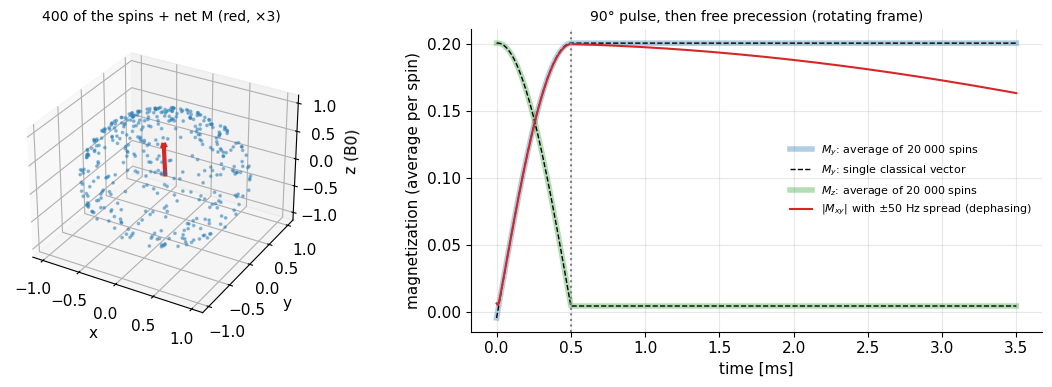

max difference ensemble average vs single vector: 1.9e-15


In [9]:
rng = np.random.default_rng(0)
n_spins, a_bias = 20000, 0.6                          # a = mu*B/(k_B T); hugely exaggerated (real: ~1e-5)
r = rng.random(n_spins)
cos_t = np.log(np.exp(-a_bias) + r * (np.exp(a_bias) - np.exp(-a_bias))) / a_bias   # sample p(cos) ~ exp(a cos)
phi = rng.uniform(0, 2 * np.pi, n_spins)
sin_t = np.sqrt(1 - cos_t**2)
spins = np.stack([sin_t * np.cos(phi), sin_t * np.sin(phi), cos_t], axis=-1)     # unit vectors
M_net = spins.mean(axis=0)
print(f"net magnetization of the ensemble: {np.round(M_net, 3)}  (theory <cos> = coth(a) - 1/a = {1 / np.tanh(a_bias) - 1 / a_bias:.3f})")

dt = 10e-6                                            # 10 us steps
T_rf = 0.5e-3                                         # 0.5 ms hard 90-degree pulse along x (rotating frame)
b1 = np.r_[np.full(int(T_rf / dt), mt.b1_for_flip(np.pi / 2, T_rf)), np.zeros(300)]   # then 3 ms free precession
t, M_ens = mt.bloch_simulate(B1=b1, dt=dt, M_init=spins)                            # every spin individually
_, M_ens_df = mt.bloch_simulate(B1=b1, dt=dt, M_init=spins, df=rng.uniform(-50, 50, n_spins))
_, M_single = mt.bloch_simulate(B1=b1, dt=dt, M_init=M_net)                         # one classical vector

fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(1, 2, 1, projection="3d")
sub = spins[:400]
ax.scatter(*sub.T, s=3, alpha=0.4)
ax.quiver(0, 0, 0, *(3 * M_net), color="C3", lw=3, arrow_length_ratio=0.15)
ax.set_title("400 of the spins + net M (red, ×3)", fontsize=10)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z (B0)")
ax2 = fig.add_subplot(1, 2, 2)
mean = lambda M: M.mean(axis=1)
for k, c in [(1, "C0"), (2, "C2")]:
    ax2.plot(t * 1e3, mean(M_ens)[:, k], c, lw=4, alpha=0.35, label=f"$M_{'xyz'[k]}$: average of 20 000 spins")
    ax2.plot(t * 1e3, M_single[:, 0, k], "k--", lw=1, label=f"$M_{'xyz'[k]}$: single classical vector" if k == 1 else None)
ax2.plot(t * 1e3, np.abs(mean(M_ens_df)[:, 0] + 1j * mean(M_ens_df)[:, 1]), "C3", label=r"$|M_{xy}|$ with ±50 Hz spread (dephasing)")
ax2.axvline(T_rf * 1e3, color="gray", ls=":")
ax2.set_xlabel("time [ms]"); ax2.set_ylabel("magnetization (average per spin)"); ax2.legend(fontsize=8)
ax2.set_title("90° pulse, then free precession (rotating frame)", fontsize=10)
plt.tight_layout(); plt.show()
print(f"max difference ensemble average vs single vector: {np.abs(mean(M_ens) - M_single[:, 0]).max():.1e}")

The average of 20 000 individually rotated spins (thick lines) is *identical* to a single classical vector (dashed): rotations are linear, so the sum of rotated vectors is the rotated sum. Each spin keeps pointing in its own direction; nothing "flips" from down to up. With a spread of precession frequencies (red), the individual transverse components fan out and their vector sum shrinks — **dephasing**, the origin of $T_2^*$ decay ([Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)).

## 8. Hyperpolarization (briefly)

Since thermal polarization is only ~10⁻⁵, why not prepare spins with a much larger, *non-equilibrium* polarization outside the scanner? That is **hyperpolarization**:

* **Dissolution DNP** (dynamic nuclear polarization): a sample (e.g. ¹³C-labelled pyruvate) is cooled to ~1 K in a strong field with a radical; microwaves transfer the much larger *electron* polarization ($|\gamma_e|\approx658\,\gamma_H$) to the nuclei; then it is dissolved rapidly and injected. Polarizations of 10–50 % — more than 10 000 × the thermal value — enable real-time imaging of metabolism (e.g. pyruvate → lactate in tumours).
* **SEOP** (spin-exchange optical pumping) for the noble gases ¹²⁹Xe and ³He: laser light polarizes rubidium electrons, which pass it on to the gas; the patient inhales it for lung ventilation imaging.
* **PHIP/SABRE** (para-hydrogen-based methods): chemistry-based alternatives.

> **🔧 Engineering reality:** Hyperpolarization is *non-renewable*. It decays toward the tiny thermal value with $T_1$ (tens of seconds for ¹³C in pyruvate), and every RF excitation uses up part of it. Sequences must therefore be fast and use small or carefully scheduled flip angles, and the polarizer must be next to the scanner. It is also why the thermal-equilibrium formulas ($M_0\propto B_0/T$) do not apply: the signal no longer grows with $B_0$ through polarization.

### 🎛️ Try it yourself

(Needs a live kernel; the static numbers above show the defaults.)

In [10]:
try:
    from ipywidgets import interact, FloatSlider, FloatLogSlider
    def _pol(B0=3.0, T_kelvin=310.0, voxel_mm=1.0):
        P = np.tanh(mt.HBAR * mt.GAMMA * B0 / (2 * mt.K_BOLTZMANN * T_kelvin))
        Nv = N_water * (voxel_mm * 1e-3)**3
        print(f"P = {P:.3e} ({P * 1e6:.2f} ppm); excess spins in a ({voxel_mm} mm)^3 water voxel: {Nv * P:.2e}; "
              f"M0 = {N_water * mt.GAMMA * mt.HBAR / 2 * P * 1e3:.3f} mA/m")
    interact(_pol, B0=FloatSlider(value=3.0, min=0.05, max=12, step=0.05),
             T_kelvin=FloatLogSlider(value=310, base=10, min=0, max=2.6), voxel_mm=FloatSlider(value=1, min=0.1, max=5, step=0.1))
except ImportError:
    print("ipywidgets not available - use the static tables above.")

interactive(children=(FloatSlider(value=3.0, description='B0', max=12.0, min=0.05, step=0.05), FloatLogSlider(…

## Where this shows up in MRI

| Concept from this refresher | Where it is used |
|---|---|
| Nuclear spin, $\gamma$, energy levels, polarization, $M_0$ formula | [Spin Physics](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| Ensemble magnetization obeys the classical Bloch equation; relaxation to thermal equilibrium | [Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| Spin density $N(\vec r)$, $M_0(\vec r)$ = "proton density" contrast | [Basic Contrast Mechanisms](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb), [In Vivo Spin Physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) |
| Signal ∝ $V_{vox}\,B_0$ (polarization) × ω0 (induction): SNR vs resolution and field | [Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb), [Advanced SNR](../pass2_deep_dive/J4_Advanced_SNR.ipynb) |
| Why manufacturers push $B_0$ higher (and its cost) | [Main Magnet Engineering](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb) |

## Key takeaways

* Nuclear spin is intrinsic, quantized angular momentum (spin number $I$); nuclei with even protons *and* even neutrons have $I=0$ and are MRI-invisible. ¹H ($I=\frac12$, largest $\gamma$, most abundant) dominates MRI.
* In $B_0$, a spin-½ has two energy levels separated by $\Delta E=\hbar\gamma B_0=h\bar\gamma B_0=hf_0$ — a photon at the Larmor frequency.
* Boltzmann: $p\propto e^{-E/k_BT}$, so $N_\uparrow/N_\downarrow=e^{\hbar\gamma B_0/k_BT}$; since $\Delta E\ll k_BT$, the polarization is $P\approx\hbar\gamma B_0/(2k_BT)$: 4.9 / 9.9 / 23 ppm at 1.5 / 3 / 7 T and 310 K.
* $M_0 = N\gamma^2\hbar^2I(I+1)B_0/(3k_BT)$ (Curie's law; identical to the original's $\bar\gamma^2h^2$ form, with $I$ instead of $I_Z$). For water at 3 T: ≈ 9 mA/m, $\mu_0M_0\approx12$ nT.
* A 1 mm³ voxel still has ~$7\times10^{14}$ excess spins: the huge spin density ($6.7\times10^{28}$ m⁻³) compensates the tiny polarization.
* "Up or down" is a misleading picture; the ensemble average obeys classical vector dynamics, which is why the Bloch equation works.
* Hyperpolarization (DNP, SEOP) boosts $P$ to 10–50 %, but it is non-renewable.

## Check your understanding

1. Which of these nuclei can be seen by MRI: ¹²C, ¹³C, ¹⁶O, ¹⁷O, ²³Na? Why?

<details><summary>Answer</summary>

¹³C ($I=\frac12$), ¹⁷O ($I=\frac52$) and ²³Na ($I=\frac32$) have non-zero spin. ¹²C and ¹⁶O have even numbers of protons and neutrons → $I=0$ → no magnetic moment, no MR signal.

</details>

2. Compute $\Delta E$ for ¹H at 3 T in joules and as a photon frequency. How does it compare with $k_BT$ at 310 K?

<details><summary>Answer</summary>

$\Delta E=\hbar\gamma B_0=1.055\times10^{-34}\cdot2.675\times10^8\cdot3\approx8.5\times10^{-26}$ J $=h\times127.7$ MHz. $k_BT=4.28\times10^{-21}$ J, about 50 000 × larger ($\Delta E/k_BT\approx2\times10^{-5}$).

</details>

3. Show that $\tanh(x/2)\approx x/2$ gives the polarization formula, and estimate the error at 3 T.

<details><summary>Answer</summary>

$P=\tanh(x/2)$ with $x=\hbar\gamma B_0/k_BT$. For small $u$, $\tanh u = u - u^3/3+\dots$, so $P\approx x/2=\hbar\gamma B_0/(2k_BT)$. At 3 T, $u\approx10^{-5}$, so the relative error $u^2/3\approx3\times10^{-11}$ — utterly negligible.

</details>

4. The original book writes $M_0 = N\bar\gamma^2h^2I_Z(I_Z+1)B_0/(3kT)$. Is this the same as $N\gamma^2\hbar^2I(I+1)B_0/(3k_BT)$?

<details><summary>Answer</summary>

Numerically yes, since $\bar\gamma h=\gamma\hbar$ and $k=k_B$ (in J/K). But the symbol should be the spin quantum number $I$ (½ for ¹H), not $I_Z$ (which denotes the $z$-component of the spin).

</details>

5. By what factor does the equilibrium magnetization of a sample change if you (a) go from 1.5 T to 7 T, (b) cool it from 310 K to 77 K (liquid nitrogen), (c) image ¹³C instead of ¹H at equal concentration?

<details><summary>Answer</summary>

(a) ∝ $B_0$: × 4.7. (b) ∝ $1/T$: × 4.0. (c) ∝ $\gamma^2$ (same $I=\frac12$): $(10.708/42.577)^2\approx0.063$, i.e. 16 × smaller (and the induced voltage, ∝ $\omega_0$, is another 4 × smaller).

</details>

6. After a perfect 90° pulse, how many spins are in the "up" state compared with "down", and how big is the transverse magnetization? What does this tell you about the "up/down" picture?

<details><summary>Answer</summary>

Measured along $z$ the populations would be equal ($M_z=0$), yet $|M_{xy}|=M_0$: all the magnetization is transverse. The up/down populations alone cannot describe this; one needs the full vector (quantum: superpositions/coherences). The vector picture — every spin's direction rotated by 90° — explains it directly.

</details>

---
*New refresher written for this adaptation; it expands the "Nuclear Spin", "Equilibrium Magnetization" and "Fractional Polarization" sections of P. Larson, "Principles of MRI" (MIT License), chapter "Spin Physics" (original DRCMR images reused). Corrected: spin number $I$ (not $I_Z$) in the $M_0$ formula, $k_B$ must be in J/K, unit of $M$ is A/m, hydrogen ≈ 63 % (not 80 %) of the body's atoms; added all derivation steps and the classical-vs-quantum discussion.*

*References:* A. Abragam, *The Principles of Nuclear Magnetism* (Oxford Univ. Press, 1961) · M. H. Levitt, *Spin Dynamics: Basics of Nuclear Magnetic Resonance* (Wiley) · L. G. Hanson, "Is quantum mechanics necessary for understanding magnetic resonance?", *Concepts Magn. Reson. A* 32, 329–340 (2008) · J. H. Ardenkjær-Larsen et al., "Increase in signal-to-noise ratio of > 10,000 times in liquid-state NMR", *PNAS* 100, 10158–10163 (2003) · D. G. Nishimura, *Principles of Magnetic Resonance Imaging* (Stanford).